In [1]:
import sys # for automation and parallelization: set manual to false when run by a launcher
MANUAL, SCENARIO = (True, 'base_timetables') if 'ipykernel' in sys.argv[0] else (False, sys.argv[1])

In [2]:
sys.path.insert(0, r'../../../quetzal')

from quetzal.model import connectionscanmodel, stepmodel
from quetzal.io import excel
import numpy as np
import pandas as pd
import geopandas as gpd

import shapely

import matplotlib.pyplot as plt
from tqdm import tqdm

In [ ]:
qpath = r'../../'
ipath = qpath + r'inputs/'
mpath = qpath + r'scenarios/{}/models/'.format(SCENARIO)

In [4]:
var = excel.read_var(ipath + r'parameters.xlsx', scenario=SCENARIO)

Index(['description', 'unit', 'category', 'parameter', 'base',
       'base_timetables'],
      dtype='object')


In [5]:
if var['run_mode']['mode'] != 'timetables':
    print('frequency scenario')
    end_of_notebook

In [6]:
NTLEG_PENALTY = var[('pathfinders_general', 'ntleg_penalty')]
TRANSFER_DURATION = var[('pathfinders_general', 'transfer_duration')]
WALK_SPEED = var[('pathfinders_general', 'walk_speed')]
TRANSFER_PENALTY = var[('pathfinders_general', 'transfer_penalty')]

CUTOFF = var[('pathfinders_timetables', 'cutoff')]
START_TIME = var[('pathfinders_timetables', 'start_time')]
END_TIME = var[('pathfinders_timetables', 'end_time')]
MIN_TRANSFER_TIME = var[('pathfinders_timetables', 'min_transfer_time')]

WALK_TIME_FACTOR = var[('mode_penalty', 'walk_time_factor')]

# READ

In [7]:
csm = connectionscanmodel.read_zippedpickles(mpath + 'zones')

zones: 100%|██████████| 14/14 [00:00<00:00, 18.24it/s]    


# NODE CLUSTERING

In [9]:
csm.preparation_clusterize_stops(distance_threshold = 200, walking_speed = WALK_SPEED) #8 
csm.nodes.set_geometry('geometry', inplace=True)

In [10]:
csm._add_type_prefixes(
        prefixes={'nodes': 'node_', 'links': 'link_' }
    )

can not add prefixes on table:  footpaths


# TIME ADJUSTMENTS

In [11]:
csm.nodes['transfer_duration'] = TRANSFER_DURATION # ON PEUT METTRE CE QU'ON VEUT, il faut juste le même pour tous les nœuds

In [12]:
def time_seconds(time_str):
    return int(time_str.split(':')[0])*3600 + int(time_str.split(':')[1])*60 + int(time_str.split(':')[2])*1

csm.links['departure_times'] = csm.links['departures'].apply(lambda x: [time_seconds(y) for y in x])
csm.links['arrival_times'] = csm.links['arrivals'].apply(lambda x: [time_seconds(y) for y in x])

links_no_geom = csm.links.drop(columns=['departure_time', 'arrival_time', 'geometry']).explode(['departure_times', 'arrival_times']).rename(columns={'departure_times': 'departure_time', 'arrival_times': 'arrival_time'}).reset_index()
links_no_geom['journey'] = links_no_geom.groupby('index').cumcount().astype(str)
links_no_geom['index_'] = links_no_geom['index'] + '_' + links_no_geom['journey']
links_no_geom['trip_id'] += '_' + links_no_geom['journey']
csm.links = gpd.GeoDataFrame(links_no_geom.merge(csm.links.reset_index()[['index', 'geometry']]), geometry='geometry', crs='EPSG:4326')
csm.links = csm.links.set_index('index_').drop(columns='index')
csm.links.index.name = 'index'

In [13]:
# On rajoute une seconde pour éviter les links 
csm.links.loc[csm.links['arrival_time'] == csm.links['departure_time'], 'arrival_time'] += 1

In [14]:
# on change les temps de départ pour qu'il correspondent au temps d'arrivée du lien précédent
to_concat = []
for trip_id in tqdm(set(csm.links['trip_id'])):
    l = csm.links.loc[csm.links['trip_id'] == trip_id]
    last_arrival_time = (l['arrival_time'] - l['arrival_time'].diff())
    l['departure_time'] = last_arrival_time.fillna(l['departure_time']) 
    to_concat.append(l)
csm.links = pd.concat(to_concat)

100%|██████████| 7553/7553 [02:13<00:00, 56.57it/s]


### Footpaths  
All stop pairs must be listed…

In [15]:
csm.preparation_dense_footpaths(max_length=500, walking_speed=3.5)
csm.footpaths['length'] = csm.footpaths.length
csm.footpaths['speed'] = (csm.footpaths['length']/csm.footpaths['duration'])*3.6

### ntlegs all zones

In [16]:
csm.zones = csm.centroids

# SHORT

In [18]:
csm.preparation_ntlegs(max_ntleg_length=5000,
                n_ntlegs=20,
                short_leg_speed=WALK_SPEED/WALK_TIME_FACTOR,
                long_leg_speed=WALK_SPEED/WALK_TIME_FACTOR,
                threshold=500,
                zone_to_transit=True,
                road_to_transit=False,
                zone_to_road=False
    )  

short_zone_to_transit = csm.zone_to_transit.copy()

In [ ]:
### TODO: ajouter les fares sur les ntlegs

In [20]:
def plot_zone_to_transit(csm):
    csm.zone_to_transit.plot.scatter('distance', 'speed')
    plt.show()
    
    ax = csm.plot('centroids', markersize=200, figsize=[50, 50])
    ax = csm.plot('nodes', markersize=20, color='black', ax=ax)
    ax = csm.plot('links', color='green', ax=ax)
    ax = csm.plot('footpaths', color='grey', ax=ax)
    ax = csm.plot('zone_to_transit', color='r', ax=ax)

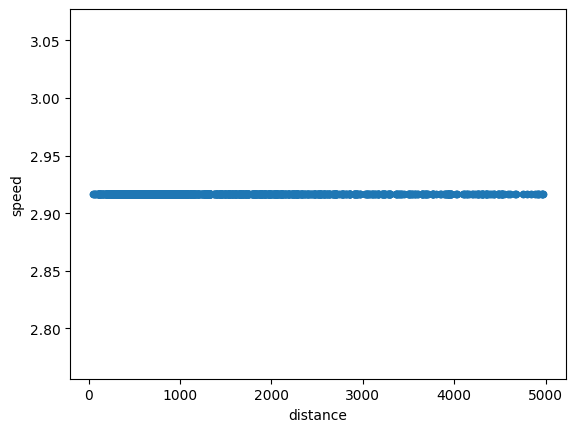

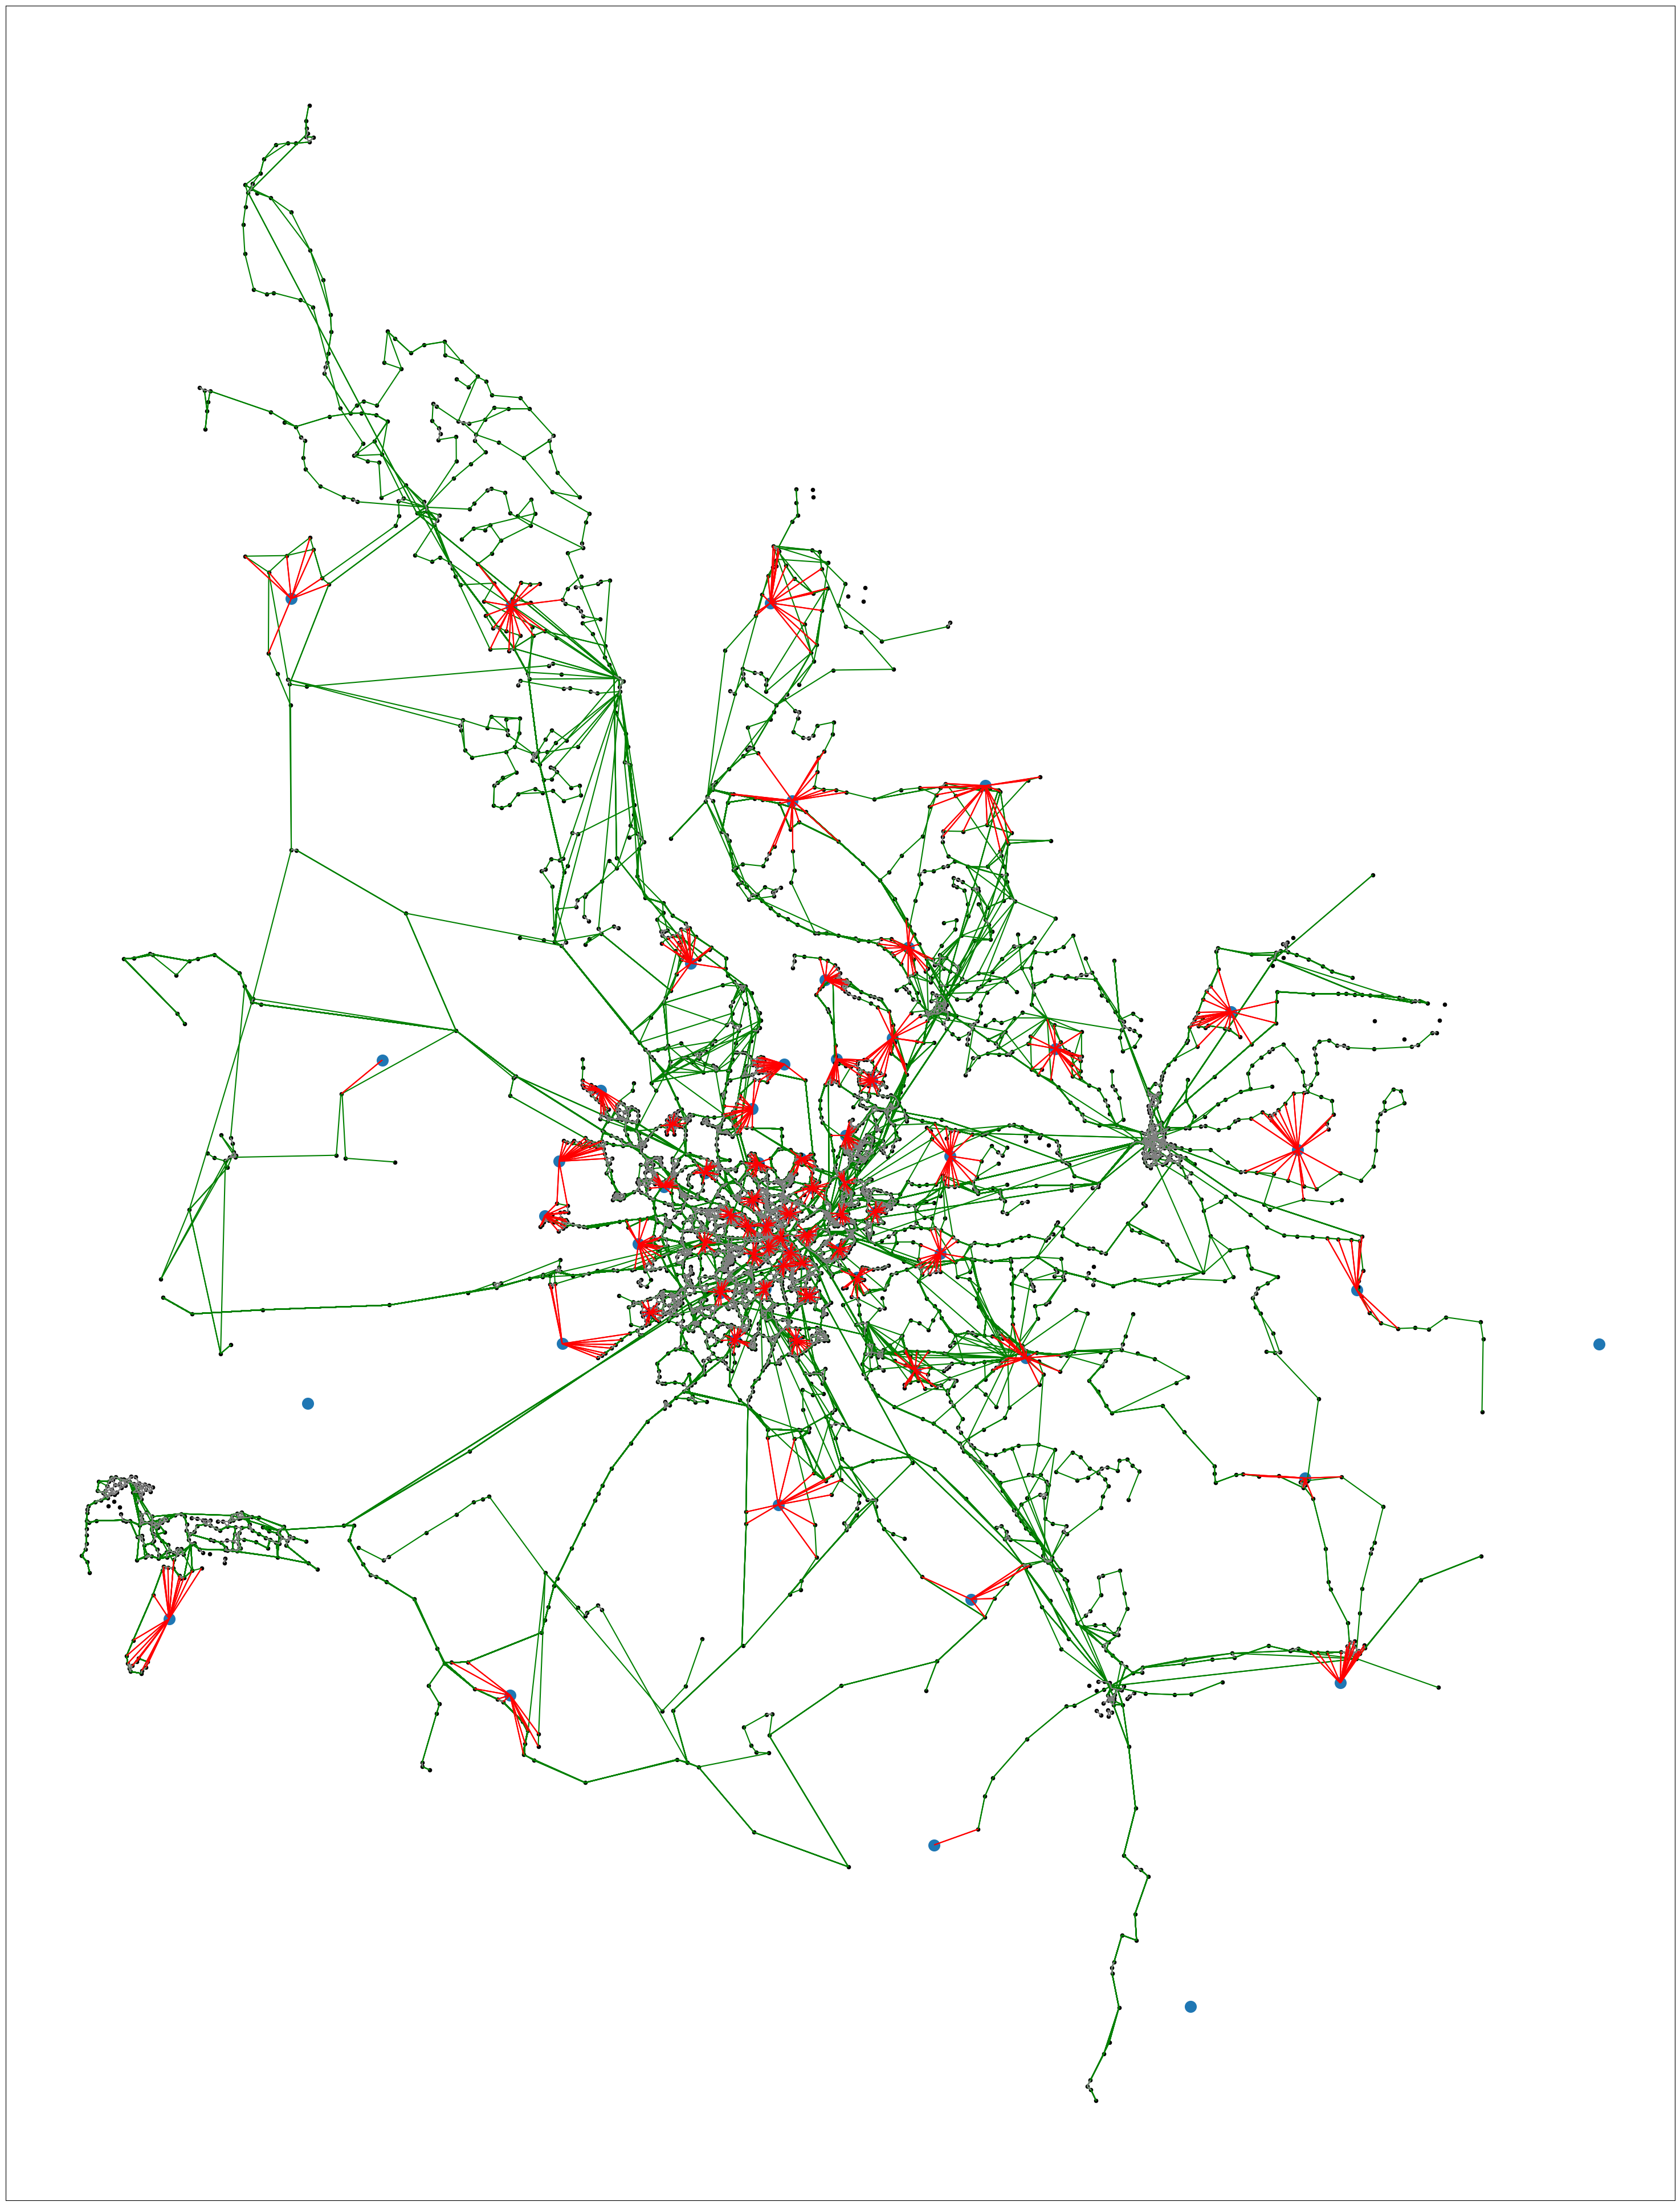

In [21]:
if MANUAL:
    plot_zone_to_transit(csm)

In [22]:
csm.zone_to_transit.loc[csm.zone_to_transit['direction'] != 'access', 'time'] += NTLEG_PENALTY
csm.zone_to_transit['str'] = [str(i) for i in csm.zone_to_transit.index]

# Add road network

In [23]:
sm_connectors = stepmodel.StepModel(crs='EPSG:2154', coordinates_unit='meter')

sm_connectors.road_links = csm.road_links.copy()
sm_connectors.road_links['time'] = sm_connectors.road_links['length']/(WALK_SPEED/3.6)
sm_connectors.road_nodes = csm.road_nodes.copy()

### Dédoubler les liens pour que les piétons puissent se déplacer dans toutes les directions suivant un lien routier
ped_links_r = sm_connectors.road_links.copy()
ped_links_r['a'], ped_links_r['b'] = ped_links_r['b'], ped_links_r['a']

sm_connectors.road_links = pd.concat([sm_connectors.road_links, ped_links_r])
sm_connectors.road_links.drop_duplicates(subset=['a', 'b'], keep='first', inplace=True)
sm_connectors.road_links = gpd.GeoDataFrame(sm_connectors.road_links, geometry='geometry', crs='EPSG:2154')

In [24]:
sm_connectors.zones = pd.concat([csm.zones, csm.nodes])

all_ods = pd.concat([csm.footpaths[['a', 'b']], csm.zone_to_transit[['a', 'b']]])
od_set_connectors = {(a, b) for a, b in zip(all_ods['a'], all_ods['b'])}

In [25]:
sm_connectors.preparation_ntlegs(
    short_leg_speed=WALK_SPEED,
    long_leg_speed=WALK_SPEED,
    zone_to_transit=False,
    zone_to_road=True,
    road_to_transit=False,
    n_ntlegs=5,
    max_ntleg_length=15000
)

sm_connectors.step_road_pathfinder(
    method='aon', 
    od_set = od_set_connectors
)

sm_connectors.analysis_car_los()
sm_connectors.analysis_car_length()

self.volumes does not exist. od generated with self.zones, od_set


In [ ]:
new_geometries = sm_connectors.car_los.copy()[['origin', 'destination', 'time', 'length', 'link_path', 'path']]
new_geometries.drop(columns='link_path', inplace=True)
all_points = pd.concat([sm_connectors.zones, sm_connectors.road_nodes])

new_geometries = new_geometries.explode('path')
new_geometries = new_geometries.merge(
    all_points['geometry'], 
    left_on='path', 
    right_index=True, 
    how='left'
)

new_geometries = new_geometries.groupby(['origin', 'destination', 'time', 'length']).agg({'geometry': shapely.geometry.LineString}).reset_index()
new_geometries.rename(columns={'origin': 'a', 'destination': 'b'}, inplace=True)

In [27]:
csm.footpaths.drop(columns=['length', 'duration', 'geometry'], inplace=True)
csm.footpaths = csm.footpaths.merge(new_geometries, on=['a', 'b'], how='left')
csm.footpaths = gpd.GeoDataFrame(csm.footpaths, geometry='geometry', crs='EPSG:2154')
csm.footpaths['duration'] = csm.footpaths['time']
csm.footpaths.index = 'footpath_' + csm.footpaths.index.astype(str)

In [28]:
csm.zone_to_transit.drop(columns=['time', 'walk_time', 'geometry'], inplace=True)
csm.zone_to_transit = csm.zone_to_transit.merge(new_geometries, on=['a', 'b'], how='left')
csm.zone_to_transit['walk_time'] = csm.zone_to_transit['time']
csm.zone_to_transit = gpd.GeoDataFrame(csm.zone_to_transit, geometry='geometry', crs='EPSG:2154')
csm.zone_to_transit.index = 'ztt_' + csm.zone_to_transit.index.astype(str)

# Pathfinder

In [29]:
def preparation_less_zone_to_transit(self):
    before = self.zone_to_transit['type'].value_counts()
    self.zone_to_transit = self.zone_to_transit.loc[
        self.zone_to_transit['a'].isin(self.nodeset()) |
        self.zone_to_transit['b'].isin(self.nodeset())
    ]
    self.zone_to_transit = self.zone_to_transit.sort_values('time').drop_duplicates(
        subset=['a', 'b'])
    self.preparation_drop_redundant_zone_to_transit()
    after = self.zone_to_transit['type'].value_counts()
    return pd.DataFrame({'before': before, 'after': after}).fillna(0).astype(int)

## Complete

In [31]:
def arrondi(x, multiple=60):
    return multiple * ((x+multiple//2)//multiple)

csm.footpaths['duration'] = csm.footpaths['duration'].apply(arrondi)
csm.zone_to_transit['time'] = csm.zone_to_transit['time'].apply(arrondi)

In [32]:
od_set = set()
for a in csm.zones.index:
    od_set = od_set.union({(a, b) for b in csm.zones.index})

In [33]:
csm.integrity_fix_nodeset_consistency()

csm.step_pt_pathfinder(
    build_connections=True, workers=16, od_set=od_set, reindex=False,
    min_transfer_time=MIN_TRANSFER_TIME, cutoff=CUTOFF, time_interval=[START_TIME, END_TIME]
)

In [35]:
csm.footpaths = pd.merge(
    csm.time_expended_footpaths,
    csm.footpaths[['geometry', 'length', 'duration', 'speed']],
    left_on = 'model_index', 
    right_index = True
)


In [36]:
csm.footpaths['model_index'] = csm.footpaths['csa_index'].copy()
csm.footpaths.set_index('csa_index', inplace=True)
csm.zone_to_transit = pd.merge(
    csm.time_expended_zone_to_transit, 
    csm.zone_to_transit[['geometry', 'speed_factor', 'short_leg_speed', 'long_leg_speed', 'speed', 'time', 'walk_time']], 
    left_on = 'model_index', 
    right_index = True
)

csm.zone_to_transit['model_index'] = csm.zone_to_transit['csa_index'].copy()
csm.zone_to_transit.set_index('csa_index', inplace=True)
csm.pseudo_connections['model_index'] = csm.pseudo_connections['csa_index'].copy()

In [37]:
csm.pt_los.value_counts(['origin', 'destination'])

origin   destination
zone_9   zone_10        124
zone_3   zone_5         111
zone_6   zone_5         111
zone_12  zone_13        110
zone_10  zone_5         107
                       ... 
zone_54  zone_59          1
         zone_55          1
         zone_53          1
         zone_51          1
         zone_40          1
Name: count, Length: 2881, dtype: int64

In [38]:
csm.analysis_paths()

100%|██████████| 45785/45785 [00:01<00:00, 38282.95it/s]


In [39]:
csm.pseudo_connections.loc[csm.pseudo_connections['direction'] == 'egress', 'arrival_time'] -= NTLEG_PENALTY
csm.pt_los[['arrival_time']] -= NTLEG_PENALTY
csm.zone_to_transit.loc[csm.zone_to_transit['direction'] != 'access', 'time'] -= NTLEG_PENALTY

In [40]:
csm.pt_los['path_hash'] = csm.pt_los['path'].apply(lambda p: hash(tuple(p)))
csm.pt_los['time'] = csm.pt_los['arrival_time'] - csm.pt_los['departure_time']
csm.pt_los = csm.pt_los.sort_values('time').drop_duplicates(subset=['path_hash'])

In [ ]:
csm.pt_los['link_path'] = csm.pt_los['path'].apply(lambda x: [link for link in x if 'link_' in link])
csm.pt_los['footpaths'] = csm.pt_los['path'].apply(lambda x: [link for link in x if 'footpath_' in link])
csm.pt_los['ntlegs'] = csm.pt_los['path'].apply(lambda x: [link for link in x if 'ztt_' in link])

csm.pt_los['itinerary_id'] = csm.pt_los.apply(lambda x: '_'.join([x['origin'], x['destination'], str(int(x['departure_time'])), str(int(x['arrival_time']))]), 1)
csm.pt_los['time'] = csm.pt_los['arrival_time'] - csm.pt_los['departure_time']
csm.pt_los['gtime'] = csm.pt_los['time'] + csm.pt_los['ntransfers']*TRANSFER_PENALTY + csm.pt_los['ntransfers'].apply(lambda x: 1e9 if x>=4 else 0)
csm.pt_los['time (mins)'] = csm.pt_los['time'] / 60
csm.pt_los = csm.pt_los.sort_values(['origin', 'destination', 'gtime', 'arrival_time'])

In [42]:
csm.pt_los['departure_hour'] = np.floor(csm.pt_los['departure_time'] / 3600).astype(int)

In [43]:
csm.pt_los['pathfinder_session'] = 'best_path'

## Add road pathfinder

In [44]:
# empty volumes
csm.volumes = pd.DataFrame(index=pd.MultiIndex.from_product([csm.zones.index]*2))
csm.volumes.index.names = ['origin', 'destination']
csm.volumes.reset_index(inplace=True)

In [45]:
csm.preparation_ntlegs(zone_to_road=True)

csm.step_road_pathfinder(method='aon')

In [46]:
csm.analysis_car_los()

In [47]:
csm.car_los['time (mins)'] = csm.car_los['time'] / 60
csm.car_los['route_type'] = 'car'
csm.car_los['pathfinder_session'] = 'best_path'

In [48]:
csm.los = pd.concat([csm.car_los, csm.pt_los])

# Save

In [49]:
csm.los.index = range(len(csm.los))

In [ ]:
csm.nodes.set_geometry('geometry', inplace=True)

In [52]:
csm.to_zippedpickles(
    mpath + 'pathfinders', max_workers=8)

los: 100%|██████████| 26/26 [00:10<00:00,  2.43it/s]                          


In [53]:
end_of_notebook

NameError: name 'end_of_notebook' is not defined

In [ ]:
od_links = csm.pt_los[['itinerary_id', 'origin', 'destination', 'departure_time', 'arrival_time', 'gtime', 'link_path']].copy()
od_links = od_links.explode('link_path')
od_links.rename(columns={'departure_time': 'itinerary_departure_time', 'arrival_time': 'itinerary_arrival_time'}, inplace=True)
od_links = od_links.merge(csm.links[['a', 'b', 'route_color', 'departure_time', 'arrival_time', 'geometry', 'time', 'speed', 'trip_id']], left_on='link_path', right_index=True)
od_links['type'] = 'link'
od_links = gpd.GeoDataFrame(od_links, geometry='geometry', crs='EPSG:2154')
print('links done')

od_ntlegs = csm.pt_los[['itinerary_id', 'origin', 'destination', 'departure_time', 'arrival_time', 'gtime', 'ntlegs']].copy()
od_ntlegs = od_ntlegs.drop(columns=['origin', 'destination'])
od_ntlegs = od_ntlegs.explode('ntlegs')
od_ntlegs.rename(columns={'departure_time': 'itinerary_departure_time', 'arrival_time': 'itinerary_arrival_time'}, inplace=True)
od_ntlegs = od_ntlegs.merge(csm.zone_to_transit[['a', 'b', 'geometry', 'departure_time', 'arrival_time', 'time', 'speed', 'trip_id']], left_on='ntlegs', right_index=True)
od_ntlegs = od_ntlegs.drop(columns='ntlegs')
od_ntlegs['route_color']='4B4B4B'
od_ntlegs['type'] = 'ntleg'
od_ntlegs = gpd.GeoDataFrame(od_ntlegs, geometry='geometry', crs='EPSG:2154')
print('ntlegs done')

od_footpaths = csm.pt_los[['itinerary_id', 'origin', 'destination', 'departure_time', 'arrival_time', 'gtime', 'footpaths']].copy()
od_footpaths = od_footpaths.drop(columns=['origin', 'destination'])
od_footpaths = od_footpaths.explode('footpaths')
od_footpaths.rename(columns={'departure_time': 'itinerary_departure_time', 'arrival_time': 'itinerary_arrival_time'}, inplace=True)
od_footpaths = od_footpaths.merge(csm.footpaths.rename(columns={"duration": 'time'})[['a', 'b' ,'geometry', 'departure_time', 'arrival_time', 'time', 'speed', 'trip_id']], left_on='footpaths', right_index=True)
od_footpaths = od_footpaths.drop(columns='footpaths')
od_footpaths['route_color']='4B4B4B'
od_footpaths['type'] = 'footpath'
od_footpaths = gpd.GeoDataFrame(od_footpaths, geometry='geometry', crs='EPSG:2154')
print('footpaths done')

od_route = pd.concat([od_links, od_footpaths, od_ntlegs])
od_route['route_color'] = od_route['route_color'].fillna('838383').replace('null', '838383')
od_route['route_color'] = od_route['route_color'].apply(lambda c: f'#{c.strip()}')
od_route['mode'] = od_route['link_path'].map(csm.links['route_type'].to_dict()).fillna('walk')
od_route = gpd.GeoDataFrame(od_route, geometry='geometry', crs='EPSG:2154')
od_route['length'] = od_route.length

# export PT lost metrics
modes = od_route['mode'].unique().tolist()
csm.analysis_pt_route_type(modes)
for mode in modes:
    temp = od_route.loc[od_route['mode'] == mode].groupby(['itinerary_id'])['time'].sum().to_dict()
    csm.pt_los['{}_time'.format(mode)] = csm.pt_los['itinerary_id'].map(temp).fillna(0)


In [ ]:
def seconds_time(total_seconds):
    total_seconds = int(total_seconds) % (24 * 3600)
    h = total_seconds // 3600
    m = (total_seconds % 3600) // 60
    #s = total_seconds % 60
    return f"{h:02d}:{m:02d}"#:{s:02d}"

In [ ]:
access_time_dict = od_route.loc[od_route['type'] == 'ntleg'].groupby(['itinerary_id'])['time'].sum().to_dict()
csm.pt_los['access_time'] = csm.pt_los['itinerary_id'].map(access_time_dict).fillna(0)

footpath_time_dict = od_route.loc[od_route['type'] == 'footpath'].groupby(['itinerary_id'])['time'].sum().to_dict()
csm.pt_los['footpath_time'] = csm.pt_los['itinerary_id'].map(footpath_time_dict).fillna(0)

csm.pt_los['waiting_time'] = csm.pt_los['time'] - csm.pt_los[['{}_time'.format(mode) for mode in modes if mode != 'walk'] + ['access_time', 'footpath_time']].sum(axis=1)

csm.pt_los['route_ids'] = csm.pt_los['link_path'].apply(lambda x: csm.links.loc[x]['route_id'].unique().tolist())
csm.pt_los['trip_ids'] = csm.pt_los['link_path'].apply(lambda x: csm.links.loc[x]['trip_id'].unique().tolist())

pt_los = csm.pt_los.copy()
relevant_cols = ['origin', 'destination', 'ntransfers', 'itinerary_id', 'departure_time', 'arrival_time', 'time (mins)', 'time', 'walk_time', 'route_types', 'route_ids', 'trip_ids']
time_cols = [col for col in csm.pt_los.columns if 'time' in col if col not in ['departure_time', 'arrival_time', 'time', 'gtime', 'time (mins)', 'walk_time']]

itineraries_to_keep = pt_los['itinerary_id'].drop_duplicates().values.tolist()
cols = relevant_cols + time_cols
pt_los = pt_los[cols]
pt_los.index.name = 'index'

length_dict = od_route.groupby('itinerary_id')['length'].sum()
pt_los['departure_time'] = pt_los['departure_time'].apply(seconds_time)
pt_los['arrival_time'] = pt_los['arrival_time'].apply(seconds_time)
pt_los['length'] = pt_los['itinerary_id'].map(length_dict)

In [ ]:
all_points = pd.concat([csm.nodes.reset_index(names='index')[['index', 'geometry']], csm.zones.reset_index(names='index')[['index', 'geometry']]])
od_route['centroid_from'] = od_route['a'].map(all_points.set_index('index')['geometry'].to_dict())
od_route['centroid_to'] = od_route['b'].map(all_points.set_index('index')['geometry'].to_dict())
od_route['geometry_'] = od_route['geometry'].copy()
od_route.loc[od_route['type'] == 'link', 'geometry'] = od_route.loc[od_route['type'] == 'link'].apply(lambda x: shapely.geometry.LineString([x['centroid_from'], x['centroid_to']]), 1)

In [ ]:
origin = 'zone_47'
destination = 'zone_67'

In [ ]:
# Png of paths
from syspy.spatial.spatial import plot_lineStrings, plot_points
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO
from shapely.geometry import Point, LineString, MultiLineString, MultiPolygon, Polygon


def lonlat_to_meters(lon, lat):
    """Convert lon/lat to meters in Web Mercator."""
    origin_shift = 2 * np.pi * 6378137 / 2.0
    mx = lon * origin_shift / 180.0
    my = np.log(np.tan((90 + lat) * np.pi / 360.0)) * 6378137
    return mx, my


def calculate_zoom_to_fit_bbox(minx, miny, maxx, maxy, target_width_px, target_height_px, tile_size=256):
    """
    Calculate the appropriate zoom level to fit a bounding box into a fixed pixel size.
    Returns an approximate integer zoom.
    """
    # Convert bbox corners to Web Mercator meters
    mx1, my1 = lonlat_to_meters(minx, miny)
    mx2, my2 = lonlat_to_meters(maxx, maxy)

    # Get span in meters
    width_m = abs(mx2 - mx1)
    height_m = abs(my2 - my1)

    # Calculate resolution required (meters per pixel)
    res_x = width_m / target_width_px
    res_y = height_m / target_height_px
    target_res = max(res_x, res_y)

    # Initial resolution at zoom 0
    initial_res = 2 * np.pi * 6378137 / tile_size

    # Compute zoom level from resolution
    zoom = np.log2(initial_res / target_res)

    return int(round(zoom))


def deg2num(lat_deg, lon_deg, zoom):
    lat_rad = np.radians(lat_deg)
    n = 2.0**zoom
    xtile = int((lon_deg + 180.0) / 360.0 * n)
    ytile = int((1.0 - np.log(np.tan(lat_rad) + 1 / np.cos(lat_rad)) / np.pi) / 2.0 * n)
    return (xtile, ytile)


def num2deg(xtile, ytile, zoom):
    n = 2.0**zoom
    lon_deg = xtile / n * 360.0 - 180.0
    lat_rad = np.atan(np.sinh(np.pi * (1 - 2 * ytile / n)))
    lat_deg = np.degrees(lat_rad)
    return (lat_deg, lon_deg)


def create_basemap(ax, image_size_px=(512, 512)):
    miny, maxy = ax.get_ylim()
    minx, maxx = ax.get_xlim()
    # Fixed image resolution
    zoom = calculate_zoom_to_fit_bbox(minx, miny, maxx, maxy, image_size_px[0], image_size_px[1])

    print(f'Zoom : {zoom}')

    x_min, y_max = deg2num(miny, minx, zoom)
    x_max, y_min = deg2num(maxy, maxx, zoom)

    width = x_max - x_min + 1
    height = y_max - y_min + 1

    # Create a blank image
    tile_size = 256
    basemap = Image.new('RGB', (width * tile_size, height * tile_size))
    # Download and stitch tiles
    for x in range(x_min, x_max + 1):
        for y in range(y_min, y_max + 1):
            url = f'http://a.basemaps.cartocdn.com/light_nolabels/{zoom}/{x}/{y}.png'
            response = requests.get(url)
            tile = Image.open(BytesIO(response.content))
            basemap.paste(tile, ((x - x_min) * tile_size, (y - y_min) * tile_size))

    # Show basemap image
    lat_top_left, lon_top_left = num2deg(x_min, y_min, zoom)
    lat_bottom_right, lon_bottom_right = num2deg(x_max + 1, y_max + 1, zoom)
    ax.imshow(basemap, extent=[lon_top_left, lon_bottom_right, lat_bottom_right, lat_top_left], aspect='equal')
    ax.set_xlim([minx, maxx])
    ax.set_ylim([miny, maxy])

od_route_export = od_route.loc[(od_route['origin'] == origin) & (od_route['destination'] == destination)]

od_route_export['departure_time'] = od_route_export['departure_time'].apply(seconds_time)
od_route_export['arrival_time'] = od_route_export['arrival_time'].apply(seconds_time)

od_route_export['itinerary_departure_time'] = od_route_export['itinerary_departure_time'].apply(seconds_time)
od_route_export['itinerary_arrival_time'] = od_route_export['itinerary_arrival_time'].apply(seconds_time)

if True:
    od_route.to_crs(epsg='4326', inplace=True)
    csm = csm.change_epsg(epsg='4326', coordinates_unit = 'degree')

    for origin, destination, itinerary_id in od_route_export[['origin', 'destination', 'itinerary_id']].drop_duplicates().values:
        fig, ax = plt.subplots(figsize=(10, 10))
        route = od_route[od_route['itinerary_id'] == itinerary_id]

        route_stations = route.loc[route['type'] == 'link'].copy()
        route_stations = route_stations[['route_color', 'geometry']]
        route_stations['node_from'] = route_stations['geometry'].apply(lambda x: Point(x.coords[0]))
        route_stations['node_to'] = route_stations['geometry'].apply(lambda x: Point(x.coords[-1]))
        route_stations_all = pd.concat([route_stations[['route_color', 'node_from']].rename(columns={'node_from': 'geometry'}), route_stations[['route_color', 'node_to']].rename(columns={'node_to': 'geometry'})])
        route_stations_all = route_stations_all.drop_duplicates()

        csm.od_basemap(origin=origin, destination=destination, squared=True, figsize=(10, 10), ax=ax)
        if len(route_stations_all) > 0:
            plot_points(route_stations_all, ax=ax, s=15, color=route_stations_all['route_color'])
        plot_lineStrings(route, ax=ax, linewidth=2, colors=route['route_color'])

        csm.zones.loc[[origin]].plot(ax=ax, color='green')
        csm.zones.loc[[destination]].plot(ax=ax, color='red')

        create_basemap(ax)

        ax.set_xticks([])
        ax.set_yticks([])

        title = f'{itinerary_id} \n'

        path = csm.pt_los[csm.pt_los['itinerary_id'] == itinerary_id].iloc[0]
        path['min'] = np.round(path['time'] / 60).astype(int)
        mins = (
            (path[time_cols + ['time']] / 60)
            .astype(int)
            .astype(str)
        )
        title += '\n' + 'departure: {}'.format(seconds_time(path['departure_time'])) + ' ; arrival {} \n'.format(seconds_time(path['arrival_time']))
        title += f'{path['min']} mins | {path['ntransfers']} transfers \n'
        for col in time_cols:
            if mins[col] != '0':
                title += '\n' + col.replace('_time', ': ') + mins[col] + ' mins'

        trip_dict = csm.links['trip_id'].to_dict()
        trip_list = route['link_path'].apply(trip_dict.get).drop_duplicates().dropna().to_list()
        title += '\n\n'
        title += ' -> '.join(trip_list)
        ax.set_title(title)

        png = f'OD_PT_{origin}_{destination}.png'

In [ ]:
### TODO: comment éviter que les gens prennent les footpaths sans que ce soit pour faire une correspondance 
# -> construire des ntlegs entre les noeuds du réseau reliés à une zone reliée à une autre par un footpath
### TODO: footpaths sans géométrie.
# -> chercher
### TODO: problèmes de rivière : certains footpaths croisent la rivière
# -> mettre un seuil de longueur sur les nouvelles géométries des footpaths.

In [ ]:
csm.pt_los.loc[csm.pt_los['itinerary_id'] == 'zone_2_zone_5_34311_36996'].path.values.tolist()[0]

In [ ]:
fp = gpd.GeoDataFrame(csm.footpaths, geometry='geometry', crs='EPSG:2154')
fp.loc['footpath_footpath_5702_36218_36546.0'].geometry

In [ ]:
csm.pt_los.loc[csm.pt_los['itinerary_id'] == 'zone_2_zone_5_24521_26377'][[
       'origin', 'destination', 'departure_time', 'arrival_time',
       'time', 'gtime', 'time (mins)',
       'departure_hour', 'tramway_time',
       'bus_time', 'rail_time', 'schoolbus_time', 'ferry_time', 'walk_time',
       'access_time', 'footpath_time', 'waiting_time', 'route_ids',
       'trip_ids']]